In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from sklearn.model_selection import train_test_split

In [2]:
(x_train, y_train), (x_test, y_test) = (
    (np.fromfile('MNIST/train-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/train-labels-idx1-ubyte', np.uint8)[8:]),
    (np.fromfile('MNIST/t10k-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/t10k-labels-idx1-ubyte', np.uint8)[8:])
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


In [3]:
x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test = x_test.reshape(-1, 784).astype('float32') / 255.0

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.1, random_state=42
)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)

Training: (54000, 784)
Validation: (6000, 784)


In [4]:
model1 = Sequential([
    tf.keras.Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history1 = model1.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_val, y_val)
)

print("Normal model training completed!")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8971 - loss: 0.3704 - val_accuracy: 0.9428 - val_loss: 0.2028
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9510 - loss: 0.1728 - val_accuracy: 0.9592 - val_loss: 0.1439
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9639 - loss: 0.1256 - val_accuracy: 0.9638 - val_loss: 0.1221
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9719 - loss: 0.0974 - val_accuracy: 0.9717 - val_loss: 0.1011
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9783 - loss: 0.0776 - val_accuracy: 0.9727 - val_loss: 0.0975
Normal model training completed!


In [5]:
model2 = Sequential([
    tf.keras.Input(shape=(784,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(10, activation='softmax')
])

model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model2.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_val, y_val)
)

print("L2 model training completed!")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8974 - loss: 0.5024 - val_accuracy: 0.9450 - val_loss: 0.3123
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9457 - loss: 0.2847 - val_accuracy: 0.9555 - val_loss: 0.2514
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9578 - loss: 0.2316 - val_accuracy: 0.9650 - val_loss: 0.2147
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9635 - loss: 0.2049 - val_accuracy: 0.9643 - val_loss: 0.1987
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9680 - loss: 0.1860 - val_accuracy: 0.9640 - val_loss: 0.1948
L2 model training completed!


In [6]:
model3 = Sequential([
    tf.keras.Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

model3.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history3 = model3.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(x_val, y_val)
)

print("Dropout model training completed!")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8735 - loss: 0.4402 - val_accuracy: 0.9395 - val_loss: 0.2161
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9356 - loss: 0.2250 - val_accuracy: 0.9542 - val_loss: 0.1544
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9493 - loss: 0.1743 - val_accuracy: 0.9630 - val_loss: 0.1260
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9577 - loss: 0.1457 - val_accuracy: 0.9695 - val_loss: 0.1062
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9626 - loss: 0.1251 - val_accuracy: 0.9712 - val_loss: 0.0947
Dropout model training completed!


In [7]:
acc1 = model1.evaluate(x_test, y_test, verbose=0)[1]
acc2 = model2.evaluate(x_test, y_test, verbose=0)[1]
acc3 = model3.evaluate(x_test, y_test, verbose=0)[1]

print("\nNormal Model Accuracy:", acc1 * 100, "%")
print("L2 Model Accuracy:", acc2 * 100, "%")
print("Dropout Model Accuracy:", acc3 * 100, "%")


Normal Model Accuracy: 97.11999893188477 %
L2 Model Accuracy: 96.35000228881836 %
Dropout Model Accuracy: 97.15999960899353 %


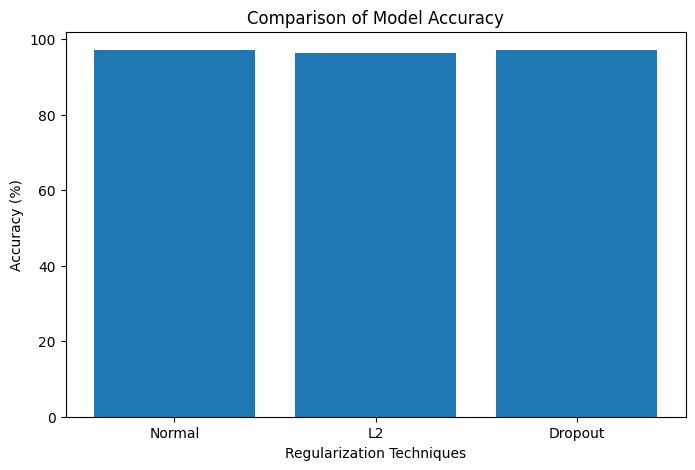

In [8]:
plt.figure(figsize=(8, 5))

plt.bar(
    ['Normal', 'L2', 'Dropout'],
    [acc1 * 100, acc2 * 100, acc3 * 100]
)

plt.title("Comparison of Model Accuracy")
plt.xlabel("Regularization Techniques")
plt.ylabel("Accuracy (%)")
plt.show()

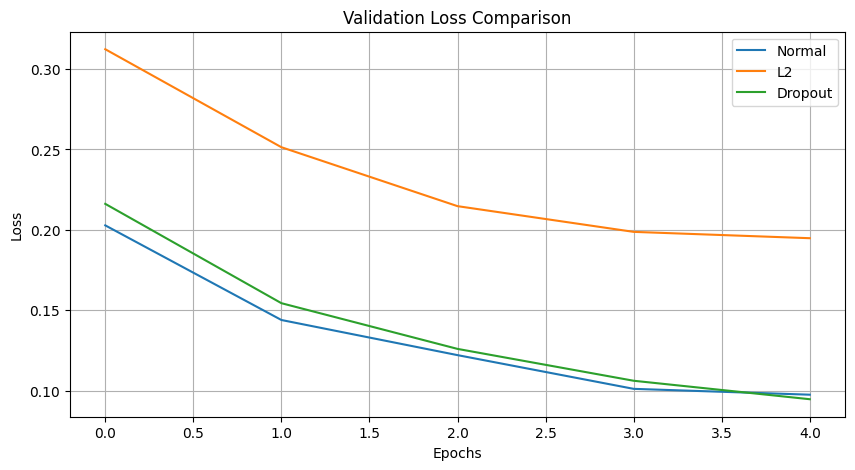

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(history1.history['val_loss'], label='Normal')
plt.plot(history2.history['val_loss'], label='L2')
plt.plot(history3.history['val_loss'], label='Dropout')

plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

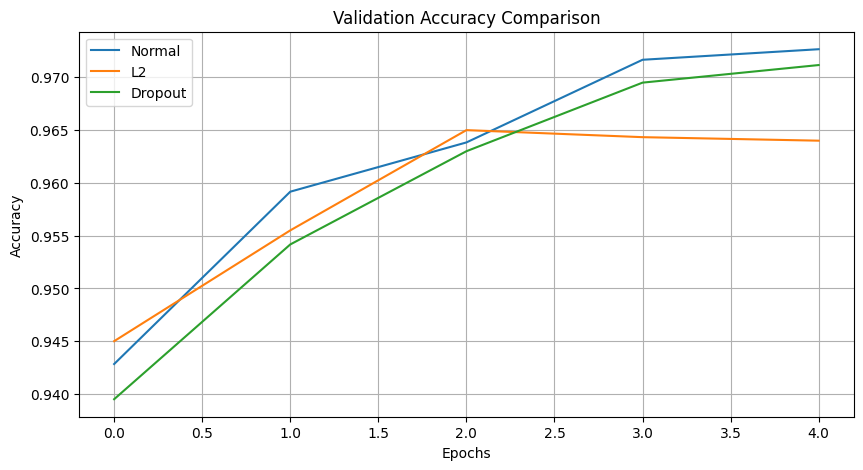

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(history1.history['val_accuracy'], label='Normal')
plt.plot(history2.history['val_accuracy'], label='L2')
plt.plot(history3.history['val_accuracy'], label='Dropout')

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()